<a href="https://colab.research.google.com/github/raghavvoid-static/Student-Grade-prediction/blob/main/student_grade_prediction_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Predicting student final gradesn (UCI Student Performance, Math).**


In [1]:
import pandas as pd
import urllib.request
import zipfile
import os

# Force download the official UCI dataset to get the correct zip structure
url = 'https://archive.ics.uci.edu/static/public/320/student+performance.zip'
urllib.request.urlretrieve(url, 'student_performance.zip')

with zipfile.ZipFile('student_performance.zip', 'r') as zip_ref:
    zip_ref.extractall('student_data')

# The dataset has student-mat.csv inside the nested structure
if os.path.exists('student_data/student.zip'):
    with zipfile.ZipFile('student_data/student.zip', 'r') as zip_ref_inner:
        zip_ref_inner.extractall('.')

df = pd.read_csv("student-mat.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
print(df.shape)
print(df.info())
print(df.isnull().sum().sum())

(395, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  

,G1,G2,G3
G1,1.000000,0.852118,0.801468
G2,0.852118,1.000000,0.904868
G3,0.801468,0.904868,1.000000


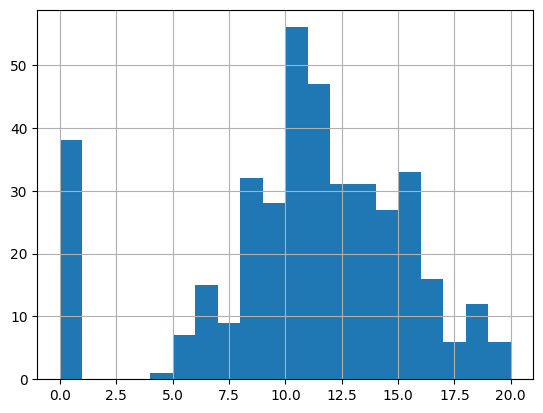

In [3]:
df["G3"].hist(bins=20)
df[["G1","G2","G3"]].corr()

 *The dataset has 395 students and 33 columns, with no missing values. G1, G2 and G3 are grades from the first period, second period and final. G3 is the target I will be predicting here. About 38 students have a final grade of 0, which shows up as a spike on the left of the histogram. The dataset doesn’t explain why, so I left those rows in. The grades are related as such: G2 and G3 at 0.90, G1 and G3 at 0.80. So G1 and G2 grades will probably dominate the G3 grade prediction.*

In [4]:
from sklearn.model_selection import train_test_split
x = pd.get_dummies(df.drop(columns=["G3"]),drop_first=True)
y = df["G3"]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
x_train.shape, x_test.shape

((316, 41), (79, 41))

In [5]:
from sklearn.metrics import mean_absolute_error, r2_score

baseline = [y_train.mean()] * len(y_test)
print("Baseline MAE:", mean_absolute_error(y_test, baseline))

Baseline MAE: 3.64585002403461


In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

def evaluate(X_train, X_test, y_train, y_test):
    models = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(random_state=42),
    }
    for name, model in models.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        print(name, "| MAE:", round(mean_absolute_error(y_test, pred), 2),
              "| R2:", round(r2_score(y_test, pred), 2))

evaluate(x_train, x_test, y_train, y_test)

Linear Regression | MAE: 1.65 | R2: 0.72
Random Forest | MAE: 1.16 | R2: 0.81


*Results with all features: The baseline of predicting the average gives an MAE of 3.65. Linear Regression gets MAE 1.65 (R2: 0.72) and Random Forest gets MAE 1.16 (R2: 0.81), so both clearly beat the baseline.*

In [7]:
x2 = x.drop(columns=["G1", "G2"])
x2_train, x2_test, _, _ = train_test_split(x2, y, test_size=0.2, random_state=42)
evaluate(x2_train, x2_test, y_train, y_test)

Linear Regression | MAE: 3.4 | R2: 0.14
Random Forest | MAE: 3.15 | R2: 0.24


*Results without G1 and G2:
Without the earlier grades, Linear Regression gets MAE 3.40 (R² 0.14) and Random Forest gets MAE 3.15 (R² 0.24). That is only slightly better than the baseline of 3.65.

Conclusion:
Almost all of the predictive power comes from the earlier grades. The other features (study time, absences, family background and so on) predict final grade poorly on their own. Random Forest did better than Linear Regression in both setups.

Limitations:
The dataset is small (395 rows) and comes from two schools.Using a single train/test split, did no hyperparameter tuning, and did not handle the grade-0 students specially.*

